## Deep Hedging Implementation: derived from "Deep Hedging" - Oxford, JPMorgan Chase (2018)

A framework for hedging a derivatives portfolio under market frictions (mainly transaction costs) using deep reinforcement learning methods.
Authors: Akshu Enaganti, Leandro Sanchez-Betancourt

### Step 1: Heston Model Simulation

The Heston model is a continuous time stochastic volatility model dependent on 2 stochastic differential equations (one for stock price, and one for variance).

Stock Price Process: $$dS^1_t = \sqrt{V_t} S^1_t dB_t$$

Variance Process (CIR): $$dV_t = \kappa(\theta - V_t)dt + \sigma\sqrt{V_t}dW_t$$

where $B_t$, $W_t$ are Brownian motions with correlation $\rho$, i.e. $d\langle B, W \rangle_t = \rho \, dt$.

The variance is sampled from its true conditional distribution, a scaled noncentral chi-squared, using the Broadie-Kaya sampling scheme (referenced in paper footnote 5).

Variance Process (Broadie-Kaya sampling):
$$V_{k+1} | V_k \sim c \cdot \chi^2(df, \lambda)$$
$$c = \frac{\sigma^2(1-e^{-\kappa \Delta t})}{4\kappa}, \quad df = \frac{4\kappa\theta}{\sigma^2}, \quad \lambda = \frac{V_k e^{-\kappa \Delta t}}{c}$$

The stock price is sampled using a simplified Broadie-Kaya scheme, replacing $V$ with a piecewise, constant process between timesteps.
$$\log\frac{S^1_{k+1}}{S^1_k} = \frac{\rho}{\sigma}\left(V_{k+1} - V_k - \kappa\theta\Delta t + \kappa V_k \Delta t\right) - \frac{1-\rho^2}{2} V_k \Delta t + \sqrt{(1-\rho^2) V_k \Delta t} \cdot Z$$

where $Z \sim \mathcal{N}(0,1)$.

Aside from the stock itself, the other tradeable instrument is a variance swap, or a contract whose price reflects total expected realized variance over [0, T], given a current variance $V_t$. The equation for the variance swap price is shown below.

Variance Swap Price (equation 5.4): $$S^2_t = \int_0^t V_s \, ds + L(t, V_t),$$ $$L(t, v) = \frac{v - \theta}{\kappa}\left(1 - e^{-\kappa(T-t)}\right) + \theta(T-t)$$

where the integral $\int_0^t V_s\, ds$ is approximated as a running sum $\sum_{j=0}^{k-1} V_j \Delta t$.

Simulating the Heston model gives a market model to exercise and validate trading strategies within.

In [1]:
!pip install QuantLib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.1/20.1 MB 88.6 MB/s eta 0:00:00


In [2]:
# Libraries
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from scipy.stats import norm, ncx2
import QuantLib as ql

In [3]:
# Data Generation (Heston Model Simulator)
def Heston(N, n=30, S0=100, v0=0.04, kappa=1.0, theta=0.04,
                    sigma=2.0, rho=-0.7, T=30/365):
    """
    [in]: num. paths (N), num. timesteps (n), init. stock price (S0),
            init. var. (v0), mean reversion speed of var. (kappa),
            long-run mean var. (theta), volatility of volatility (sigma),
            corr. between stock price and var. moves (rho),
            time horizon in years (T)
    [out]: stock (S1), var. swap (S2), var. process (V)

    Simulate N paths of Heston model over n timesteps.
    """

    dt = T/n

    # Shape of output sequences: N paths, n+1 timesteps
    S1 = np.zeros((N, n+1))
    S2 = np.zeros((N, n+1))
    V = np.zeros((N, n+1))

    # Initial values on each path: S0, v0
    S1[:, 0], V[:, 0] = S0, v0

    for k in range(n):
        # CIR sampling: V_{k+1} | V_k formula
        c = sigma**2 * (1 - np.exp(-kappa * dt)) / (4 * kappa)
        df = 4 * kappa * theta / sigma**2
        nc = V[:, k] * np.exp(-kappa * dt) / c

        V[:, k+1] = c * ncx2.rvs(df=df, nc=nc, size=N)

        # Broadie-Kaya sampling for S: integral of V_s ds ≈ V_k * dt
        int_V = V[:, k] * dt

        Z = np.random.normal(0, 1, N)
        log_S = (rho / sigma * (V[:, k+1] - V[:, k]
                                - kappa * theta * dt
                                + kappa * int_V)
                    - 0.5 * (1 - rho**2) * int_V
                    + np.sqrt(np.maximum((1 - rho**2) * int_V, 0)) * Z)
        S1[:, k+1] = S1[:, k] * np.exp(log_S)

    # Variance swap price (equation 5.4: S2t = integral from 0 to t (Vs ds) + L(t, Vt))
        # L(t, v): (v-theta)/kappa * (1-e^(-kappa(T-t))) + theta*(T-t)
    t_grid = np.linspace(0, T, n+1) # 0/365 -> 30/365

    for k in range(n+1):
        t = t_grid[k]
        L = ((V[:, k] - theta) / kappa) * (1 - np.exp(-kappa * (T - t))) + theta * (T - t)

        # Approximation of integral: sum * dt
        re_var = np.sum(V[:, :k], axis=1) * dt if k > 0 else 0

        # Variance swap: sum of past realized var., expected realized var.
        S2[:, k] = re_var + L

    return S1, S2, V

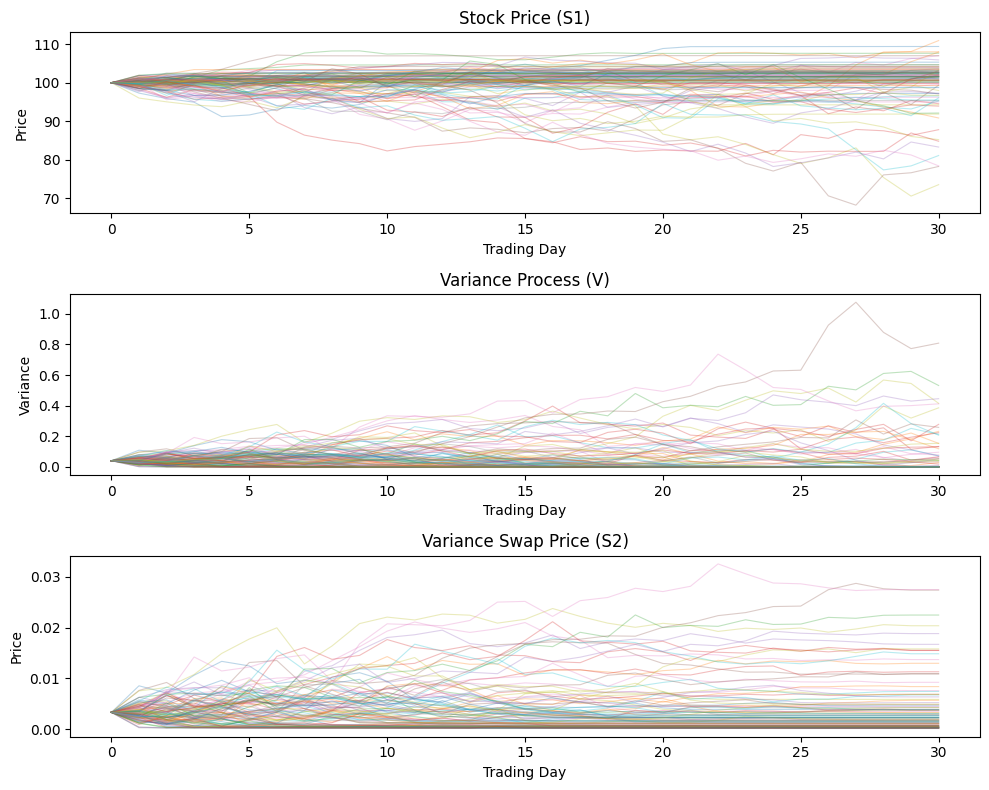

In [4]:
# Added visuals for Heston model process
import matplotlib.pyplot as plt

S1, S2, V = Heston(N=1000)

fig, axes = plt.subplots(3, 1, figsize=(10, 8))

# 100 sample paths for each
axes[0].plot(S1[:100].T, alpha=0.3, linewidth=0.8)
axes[0].set_title('Stock Price (S1)')
axes[0].set_xlabel('Trading Day')
axes[0].set_ylabel('Price')

axes[1].plot(V[:100].T, alpha=0.3, linewidth=0.8)
axes[1].set_title('Variance Process (V)')
axes[1].set_xlabel('Trading Day')
axes[1].set_ylabel('Variance')

axes[2].plot(S2[:100].T, alpha=0.3, linewidth=0.8)
axes[2].set_title('Variance Swap Price (S2)')
axes[2].set_xlabel('Trading Day')
axes[2].set_ylabel('Price')

plt.tight_layout()
plt.show()

### Step 2: Recurrent Neural Network

In markets with friction, the optimal hedging strategy $\delta^*$ is an unknown function from market state to optimal holdings, at each timestep. The goal of the neural networks is to approximate $\delta^*$, as analytically solving for it is implausible. From Hornik's 1991 work, any continuous function can be approximated by a sufficiently large neural network, arbitrarily well enough.

Each network, at each timestep $k$, takes in current market information and the previous position ($\delta_{k-1}$), outputting the new position.
$$\delta_k = F^{\theta_k}(I_k, \delta_{k-1}),$$
$$I_k = (\log S^1_k, V_k)$$

Transaction costs are dependent upon the change in position, necessitating the inclusion of $\delta_{k-1}$ in the networks.
$$C_T(\delta) = \sum_{k=0}^{n} \varepsilon |\delta_k - \delta_{k-1}| \cdot S^i_k$$

$n = 30$ distinct networks are used, one per trading day; each network independently learns its parameters $\theta_k$, modeling the optimal strategy on day $k$ (which, naturally, differs from the optimal strategy on day $k+1$). These networks are chained together; the output $\delta_k$ of network $k$ feeds as input into network $k+1$, allowing gradients to flow back through time through training.

In [5]:
# Neural Network Trading Strategies
class tradingStrategy(nn.Module):
    """
    [in]: market state (size=d), prev. position (size=d)
    [out]: new position (size=d)

    Neural network for a single day's trading strategy. Num. hedging
    instruments: d=2 (stock, variance swap). Two hidden layers of size
    d+15. Activation via ReLU (ReLU(x) = max(0, x)), batch normalization
    to normalize outputs of layer prior to activating.
    """
    def __init__(self, d=2):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_features=2*d, out_features=d+15), # input: market state, prev. pos. (2d); output: first hidden layer (d+15)
            nn.BatchNorm1d(num_features=d+15),
            nn.ReLU(),

            nn.Linear(in_features=d+15, out_features=d+15), # input: first hidden layer (d+15); output: second hidden layer (d+15)
            nn.BatchNorm1d(num_features=d+15),
            nn.ReLU(),

            nn.Linear(in_features=d+15, out_features=d) # input: second hidden layer (d+15); output: new pos. (d)
        )

    # Forward pass
    def forward(self, x):
        return self.net(x)

class Hedge(nn.Module):
    """
    [in]: trading timesteps (n=30), market state (size=d), prev. position (size=d)
    [out]: new position (size=d)

    Full model of n separate neural networks, one at each timestep.
    Models optimal trading decision going forward, given market
    state and curr. holdings. Semi-recurrent structure derived from
    equation 4.1: delta_k = F^{theta_k}(I_k, delta_{k-1}).
    """
    def __init__(self, n=30, d=2):
        super().__init__()
        self.n = n
        self.d = d

        # ModuleList of n separate networks, indep. & distinct weights
        self.networks = nn.ModuleList(
            [tradingStrategy(d=d) for _ in range(n)]
        )

    def forward(self, I, S):
        """
        [in]: network input I; shape: (B, n+1, d)
            I[:, :] = [log S1, V],
            market paths S; shape: (B, n+1, d)
            S[:, k, 0] = stock price S1 at timestep k,
            S[:, k, 1] = var. swap price S2 at timestep k

        [out]: holdings deltas; shape: (B, n, d)
            deltas[:, k, :] = holdings at timestep k

        Forward pass through all n timesteps/networks.
        """
        B = I.shape[0] # batch size

        # Initial pos.: 0 holdings
        delta_prev = torch.zeros(B, self.d, device=I.device)

        deltas = []
        for k in range(self.n):
            # Concatenate log market state (stabilize), prev. pos.: shape (B, 2d)
            I_k = I[:, k, :]
            x = torch.cat([I_k, delta_prev], dim=1)

            delta_k = self.networks[k](x)

            deltas.append(delta_k)
            delta_prev = delta_k

        # Shape transform: list of n (B, d) tensors -> (B, n, d)
        return torch.stack(deltas, dim=1)

In [6]:
# Verify NN with dummy inputs
model = Hedge(n=30, d=2)
I_test = torch.randn(256, 31, 2)
S_test = torch.ones(256, 31, 2) * 100
deltas = model(I_test, S_test)
print(f"Output shape: {tuple(deltas.shape)} (expected: (256, 30, 2))")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Output shape: (256, 30, 2) (expected: (256, 30, 2))
Total parameters: 14,850


### Step 3: Convex Risk Measures

Consider the terminal profit and loss (P&L) under market frictions (sum of gains/losses from trades, premium charged, call option payoff cost, and transaction costs).
$$PL_T(Z, p_0, \delta) = -Z + p_0 + (\delta \cdot S)_T - C_T(\delta)$$

Regardless of what strategy is used, the terminal P&L will be random (due to the derivative prices in trades), and this demands a measure of how desirable a distribution of outcomes is. A convex risk measure $\rho(X)$ is defined as the minimum amount of cash that must be injected into position $X$ to make it "acceptable" ($\rho(X) \leq 0$). The convex risk measure satisfies three properties:
- Monotone: if X is always a better position than Y, X must require less cash injection
- Convex: a portfolio that is half A, half B is not riskier than the average individual risk of A and B
- Cash-invariant: adding $\$c$ in cash reduces risk by exactly $\$c$

In turn, this creates the optimization problem (and loss function) for the training procedure.
$$\pi(X) = \inf_{\delta \in H} \rho\left(X + (\delta \cdot S)_T - C_T(\delta)\right)$$

$\pi(X)$ then represents the minimum achievable risk given an asset position $X$. This acts as the loss function; the networks attempt to find a trading strategy minimizing risk. The indifference price, defined as $p(Z) = \pi(-Z) - \pi(0)$, is the extra risk incurred from selling Z (difference of min. risk faced when selling derivative/hedging and min. risk faced when trading optimally distinctly). This indifference price, as shown later, is computed using two separately trained models: one that minimizes risk under liability $Z$ for $\pi(-Z)$, and one that minimizes risk with no liability for $\pi(0)$. $p(Z)$ is typically charged to the client as a premium to compensate for the risk. To verify this, consider the case where $C_T = 0$. Then, $PL = 0$ with the optimal trading strategy, giving $\pi(-Z) = p_0 + \pi(0)$ or $p(Z) = p_0$ (the standard frictionless market result).

Two different risk measures are used in this implementation, as detailed below.

- CVaR: represents the expected shortfall or tail risk; average loss over worst $\alpha\%$ of outcomes. A higher $\alpha$ means a more risk averse position, where $\alpha = 0.5$ recovers behaviour close to the model delta hedge.
$$\rho(X) = \frac{1}{1-\alpha} \int_0^{1-\alpha} \text{VaR}_\gamma(X) \, d\gamma$$

- Entropic: similar to exponential utility. A higher $\lambda$ means a more risk averse position; a nice result is that as $\lambda \rightarrow 0$, $\rho(X) \rightarrow -E[X]$, which is the pure expected value of the asset without considering risk.
$$\rho(X) = \frac{1}{\lambda} \log \mathbb{E}\left[e^{-\lambda X}\right]$$

In [7]:
# Risk Measures
def CVaR(PL, alpha=0.5):
    """
    [in]: terminal P&L for batch (PL), risk aversion level (alpha)
    [out]: CVaR risk measure

    Compute CVaR, or average loss in worst (1-alpha)% of scenarios.
    Derived from equation 3.5 in paper.
    """
    losses = -PL
    VaR = torch.quantile(losses, alpha)
    return losses[losses >= VaR].mean()

def entropic(PL, lam=1.0):
    """
    [in]: terminal P&L for batch (PL), risk aversion parameter (lam)
    [out]: entropic risk measure

    Compute entropic risk measure, or exponential utility.
    Derived from equation 3.4 in paper.
    """
    x = -lam * PL
    max_x = x.max()
    return (1/lam) * (max_x + torch.log(torch.mean(torch.exp(x - max_x))))

def compute_PL(S, deltas, Z, p0, epsilon=0.0):
    """
    [in]: market paths (S), positions (deltas), option payoff (Z),
          premium charged (p0), transaction costs (epsilon)
    [out]: terminal P&L

    Computes terminal P&L (equation 2.1, as shown above).
    """
    # Compute cumulative trading gains: sum over k (delta_k * (S_(k+1) - S_k))
    dS = S[:, 1:, :] - S[:, :-1, :]
    trading_diffs = (deltas * dS).sum(dim=(1, 2))

    # Compute transaction costs: epsilon * |delta_k - delta_(k-1)| * S_k
    B, n, d = deltas.shape
    delta_prev = torch.zeros(B, 1, d, device=deltas.device)
    delta_full = torch.cat([delta_prev, deltas], dim=1)

    delta_changes = delta_full[:, 1:, :] - delta_full[:, :-1, :]
    transaction_costs = epsilon * (torch.abs(delta_changes) * S[:, :-1, :]).sum(dim=(1, 2))

    return -Z + p0 + trading_diffs - transaction_costs

### Step 4: Model Training

The training loop is where the model "learns" the art of approximating an optimal strategy, after which its results can be evaluated in the testing stage. The full training loop is described below.

1. Sample a batch of market paths from Heston model simulator
2. Run each path through the 30 networks, outputting holdings $\delta_k$ at each timestep
3. Compute terminal P&L for batch
4. Evaluate risk measure $\rho$ on distribution of P&L outcomes
5. Backpropagate to update network weights based on loss function (Adam optimizer)

As mentioned earlier, terminal P&L is defined as follows.
$$PL_T(Z, p_0, \delta) = -Z + p_0 + (\delta \cdot S)_T - C_T(\delta)$$

The term $(\delta \cdot S)_T$ simply represents cumulative trading gains, broken down below.
$$(\delta \cdot S)_T = \sum_{k=0}^{n-1} \delta_k \cdot (S_{k+1} - S_k)$$

To model transaction costs, a proportional model is used, where transaction costs are a function of the change in position and asset price.
$$C_T(\delta) = \sum_{k=0}^{n} \varepsilon \sum_{i=1}^{d} |\delta^i_k - \delta^i_{k-1}| \cdot S^i_k$$



The loss function is a chosen risk measure, evaluated on the terminal P&L distribution across batch. A learning rate of 0.005 and batch size of 256 are used as standard hyperparameters for neural network training. The parameters are updated via the Adam optimizer, which allows for an adaptive learning rate across different parameters and tracks a momentum that simplifies gradient descent with magnitude.

In [8]:
# Training
np.random.seed(42)
torch.manual_seed(42)

def train(N=50000, n_epochs=200000, batch_size=256, lr=0.005,
          epsilon=0.0, risk_measure='cvar', alpha=0.5, lam=1.0,
          K=100, T=30/365, n=30):
    """
    [in]: num. paths (N), num. epochs (n_epochs), batch size (batch_size),
          learning rate (lr), transaction cost (epsilon),
          risk measure (risk_measure), CVaR level (alpha),
          entropic parameter (lam), strike (K), time horizon (T),
          num. timesteps (n)
    [out]: trained model, losses

    Full training loop for series of neural networks.
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Heston model simulation
    S1, S2, V = Heston(N=N, n=n, T=T)
    S1_t = torch.tensor(S1, dtype=torch.float32)
    S2_t = torch.tensor(S2, dtype=torch.float32)
    V_t = torch.tensor(V, dtype=torch.float32)

    I = torch.stack([torch.log(S1_t), V_t], dim=2) # shape: (N, n+1, 2)
    S_trade = torch.stack([S1_t, S2_t], dim=2)

    # Derivative payoff: (S1_T - K)+ for std. Eur. call option
    Z = torch.tensor(np.maximum(S1[:, -1] - K, 0), dtype=torch.float32)

    # Load to GPU
    I = I.to(device)
    S_trade = S_trade.to(device)
    Z = Z.to(device)
    model = Hedge(n=n, d=2).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Risk neutral price: p0 = E[Z]
    p0 = Z.mean().item()

    # Training loop
    losses = []
    for epoch in range(n_epochs):
        indexes = torch.randperm(N)[:batch_size]
        I_batch = I[indexes]
        S_batch = S_trade[indexes]
        Z_batch = Z[indexes]

        # Forward pass: holdings at each timestep
        model.train()
        deltas = model(I_batch, S_batch)

        # Compute terminal P&L
        PL = compute_PL(S_batch, deltas, Z_batch, p0, epsilon)

        # Chosen risk measure for loss
        if risk_measure == 'cvar':
            loss = CVaR(PL, alpha=alpha)
        else:
            loss = entropic(PL, lam=lam)

        # Backpropagate, update
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        losses.append(loss.item())

        if epoch % 5000 == 0:
            print(f"epoch {epoch}/{n_epochs} | loss: {loss.item():.4f}")

        # Checkpoint saving
        if epoch % 50000 == 0 and epoch > 0:
            torch.save(model.state_dict(), f'/content/checkpoint_{epoch}.pt')
            print(f"  Checkpoint saved at epoch {epoch}")

    model.train()
    with torch.no_grad():
        # Process in batches to update running stats
        for i in range(0, N, batch_size):
            end = min(i + batch_size, N)
            _ = model(I[i:end], S_trade[i:end])

    return model, I, S_trade, S1, V, Z, p0, losses

def compute_indifference_price(N=20000, n_epochs=5000, epsilon=0.0,
                               risk_measure='entropic', alpha=0.5, lam=1.0,
                               K=100, T=30/365, n=30, batch_size=256):
    """
    [in]: num. paths (N), num. epochs (n_epochs),
          transaction cost (epsilon), risk measure (risk_measure),
          CVaR level (alpha), entropic parameter (lam), strike (K),
          time horizon (T), timesteps (n), batch size (batch_size)
    [out]: indifference price

    Computes indifference price from two separately trained models
    for 0, Z.
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Generate paths
    S1, S2, V = Heston(N=N, n=n, T=T)
    S1_t = torch.tensor(S1, dtype=torch.float32)
    S2_t = torch.tensor(S2, dtype=torch.float32)
    V_t = torch.tensor(V, dtype=torch.float32)

    I = torch.stack([torch.log(S1_t), V_t], dim=2)
    S_trade = torch.stack([S1_t, S2_t], dim=2)

    Z = torch.tensor(np.maximum(S1[:, -1] - K, 0), dtype=torch.float32)
    p0 = Z.mean().item()

    # GPU management
    I = I.to(device)
    S_trade = S_trade.to(device)
    Z = Z.to(device)

    # Train model for Z
    model_Z = Hedge(n=n, d=2).to(device)
    optimizer_Z = optim.Adam(model_Z.parameters(), lr=0.005)

    for epoch in range(n_epochs):
        idx = torch.randperm(N, device=device)[:batch_size]
        model_Z.train()
        deltas = model_Z(I[idx], S_trade[idx])
        PL = compute_PL(S_trade[idx], deltas, Z[idx], p0, epsilon)

        loss = entropic(PL, lam) if risk_measure == 'entropic' else CVaR(PL, alpha)

        optimizer_Z.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_Z.parameters(), max_norm=1.0)
        optimizer_Z.step()

        if epoch % 10000 == 0 and epoch > 0:
            torch.save(model_Z.state_dict(), f'/content/checkpoint_Z_{epoch}.pt')
            print(f"  Checkpoint Z saved at epoch {epoch}")

    # Update BN stats
    model_Z.train()
    with torch.no_grad():
        for i in range(0, N, batch_size):
            end = min(i + batch_size, N)
            _ = model_Z(I[i:end], S_trade[i:end])

    # Train model for Z=0
    model_0 = Hedge(n=n, d=2).to(device)
    optimizer_0 = optim.Adam(model_0.parameters(), lr=0.005)

    for epoch in range(n_epochs):
        idx = torch.randperm(N, device=device)[:batch_size]
        model_0.train()
        deltas = model_0(I[idx], S_trade[idx])
        PL = compute_PL(S_trade[idx], deltas, torch.zeros(len(idx), device=device), 0.0, epsilon)

        loss = entropic(PL, lam) if risk_measure == 'entropic' else CVaR(PL, alpha)

        optimizer_0.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_0.parameters(), max_norm=1.0)
        optimizer_0.step()

        if epoch % 10000 == 0 and epoch > 0:
            torch.save(model_0.state_dict(), f'/content/checkpoint_0_{epoch}.pt')
            print(f"  Checkpoint 0 saved at epoch {epoch}")

    # Update BN stats
    model_0.train()
    with torch.no_grad():
        for i in range(0, N, batch_size):
            end = min(i + batch_size, N)
            _ = model_0(I[i:end], S_trade[i:end])

    # Evaluate both on same paths
    model_Z.eval()
    model_0.eval()
    with torch.no_grad():
        all_PL_Z, all_PL_0 = [], []
        for i in range(0, N, batch_size):
            end = min(i + batch_size, N)
            dZ = model_Z(I[i:end], S_trade[i:end])
            d0 = model_0(I[i:end], S_trade[i:end])

            all_PL_Z.append(compute_PL(S_trade[i:end], dZ, Z[i:end], p0, epsilon))
            all_PL_0.append(compute_PL(S_trade[i:end], d0, torch.zeros(end-i, device=device), 0.0, epsilon))

        PL_Z,PL_0 = torch.cat(all_PL_Z), torch.cat(all_PL_0)

        if risk_measure == 'entropic':
            pi_Z = entropic(PL_Z, lam)
            pi_0 = entropic(PL_0, lam)
        else:
            pi_Z = CVaR(PL_Z, alpha)
            pi_0 = CVaR(PL_0, alpha)

    return (pi_Z - pi_0).item()

### Step 5: Results

After the deep learning model is trained on the Heston model paths, its performance is evaluated using 3 experiments, to verify the results against those achieved by the researchers.

1. **No Transaction Costs**: the deep hedging model is evaluated against the classical model delta hedge, computed via the QuantLib library. A market without transaction costs (frictionless market) implies the classical model delta hedge is the "benchmark" hedge that the network should aim to learn. At $\alpha=0.5$ CVaR the deep hedge should reproduce the model hedge almost perfectly. The equation is shown below, where $u(t, s, v)$ is the Heston model option price and $L(t, v)$ is the variance swap formula (equation 5.4).

$$\delta^1_t = \partial_s u(t, S^1_t, V_t), \quad \delta^2_t = \frac{\partial_v u(t, S^1_t, V_t)}{\partial_v L(t, V_t)}$$

2. **Risk Aversion**: two distinct CVaR levels are compared ($\alpha = 0.5$ vs $\alpha = 0.99$) to gather insight into how the model reacts with greater risk aversion. With a higher risk aversion factor, the model should adapt a more conservative strategy, leading to a higher indifference price and smaller tail losses (but a larger mean loss).

3. **Transaction Costs**: after training at different $\varepsilon$ values, $\log(p_\varepsilon - p_0)$ is plotted against $\log(\varepsilon)$, and should produce a line of slope $\approx 2/3$. This number is quite prevalent in problems involving proportional transaction costs, and serves as a strong validator of the model's predictions.

In [9]:
# Results
def compute_delta_hedge(S1, V, K, T, n, kappa=1.0, theta=0.04,
                        sigma=2.0, rho=-0.7):
    """
    [in]: stock paths (S1), variance paths (V), strike price (K),
          time horizon (T), timesteps (n)
    [out]: model delta hedge positions

    Benchmark delta hedge, computed via QuantLib.
    """
    if isinstance(S1, torch.Tensor): S1 = S1.numpy()
    if isinstance(V, torch.Tensor): V = V.numpy()

    day_count = ql.Actual365Fixed()
    today = ql.Date.todaysDate()
    ql.Settings.instance().evaluationDate = today
    flat_ts = ql.YieldTermStructureHandle(ql.FlatForward(today, 0.0, day_count))
    div_ts = ql.YieldTermStructureHandle(ql.FlatForward(today, 0.0, day_count))
    payoff = ql.PlainVanillaPayoff(ql.Option.Call, K)

    B = S1.shape[0]
    t_grid = np.linspace(0, T, n+1)
    deltas = np.zeros((B, n, 2))

    # Loop over all timesteps, all paths
    for k in range(n):
        tau = T - t_grid[k]
        if tau < 1e-6: continue
        days_left = max(int(round(tau * 365)), 1)
        mat_date = today + ql.Period(days_left, ql.Days)
        exercise = ql.EuropeanExercise(mat_date)
        dvL = (1 / kappa) * (1 - np.exp(-kappa * tau))

        for m in range(B):
            s, v = float(S1[m, k]), float(max(V[m, k], 1e-6))
            ds, dv = 0.01, 0.0001

            def price_at(s_val, v_val):
                sh = ql.QuoteHandle(ql.SimpleQuote(s_val))
                proc = ql.HestonProcess(flat_ts, div_ts, sh, v_val, kappa, theta, sigma, rho)
                mod = ql.HestonModel(proc)
                eng = ql.AnalyticHestonEngine(mod)
                opt = ql.VanillaOption(payoff, exercise)
                opt.setPricingEngine(eng)
                return opt.NPV()

            # Compute deltas, handle exceptions
            try:
                deltas[m, k, 0] = (price_at(s+ds, v) - price_at(s-ds, v)) / (2*ds)
                dv_price = (price_at(s, v+dv) - price_at(s, v-dv)) / (2*dv)
                deltas[m, k, 1] = dv_price / dvL
            except:
                deltas[m, k, 0] = 0.5
                deltas[m, k, 1] = 0.0

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    return torch.tensor(deltas, dtype=torch.float32).to(device)

def run_results(model, I, S_trade, S1, V, Z, p0, losses,
                epsilon=0.0, alpha=0.5, K=100, T=30/365, n=30):
    """
    Training loss curve, comparison of deep hedge to model delta hedge,
    and summary of key statistics.
    """

    # Training loss plotted
    plt.figure(figsize=(8, 4))
    plt.plot(losses)
    plt.title('Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Risk Measure')
    plt.tight_layout()
    plt.show()

    # Deep hedge P&L (full dataset)
    model.eval()
    with torch.no_grad():
        all_deltas = []
        for i in range(0, len(I), 256):
            end = min(i + 256, len(I))
            all_deltas.append(model(I[i:end], S_trade[i:end]))
        deltas_deep = torch.cat(all_deltas, dim=0)
    PL_deep = compute_PL(S_trade, deltas_deep, Z, p0, epsilon)

    # Model hedge (subset)
    N_eval = min(5000, len(S1))
    print(f"Computing QuantLib hedge on {N_eval} paths...")
    deltas_model = compute_delta_hedge(S1[:N_eval], V[:N_eval], K, T, n)
    PL_model = compute_PL(S_trade[:N_eval], deltas_model, Z[:N_eval], p0, epsilon)
    PL_deep_sub = PL_deep[:N_eval]  # match subset for histogram

    # Error distributions (subset)
    plt.figure(figsize=(10, 5))
    plt.hist(PL_deep_sub.cpu().numpy(), bins=100, alpha=0.5, label=f'Deep Hedge (alpha={alpha})', density=True)
    plt.hist(PL_model.cpu().numpy(), bins=100, alpha=0.5, label='Model Delta Hedge', density=True)
    plt.axvline(x=0, color='black', linestyle='--', alpha=0.5)
    plt.title('Hedging Error Distribution')
    plt.xlabel('Terminal P&L')
    plt.ylabel('Density')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Statistics
    print(f"{'Metric':<20} {'Deep Hedge':>15} {'Model Hedge':>15}")
    print("-" * 50)
    print(f"{'Mean P&L':<20} {PL_deep_sub.mean().item():>15.4f} {PL_model.mean().item():>15.4f}")
    print(f"{'Std P&L':<20} {PL_deep_sub.std().item():>15.4f} {PL_model.std().item():>15.4f}")
    print(f"{'CVaR (95%)':<20} {CVaR(PL_deep_sub, 0.95).item():>15.4f} {CVaR(PL_model, 0.95).item():>15.4f}")
    print(f"{'Min P&L':<20} {PL_deep_sub.min().item():>15.4f} {PL_model.min().item():>15.4f}")

    return PL_deep, PL_model

def tc_exp(epsilons=None, N=20000, n_epochs=50000,
           lam=1.0, K=100, T=30/365, n=30):
    """
    [in]: transaction costs (epsilons), num. paths (N), num.
          epochs (n_epochs), entropic parameter (lam),
          strike price (K), time horizon (T), timesteps (n)
    [out]: prices, slope of log plot

    Verification of O(epsilon^(2/3)) price result (equation 5.8).
    Trains at different epsilon values, and plots log(p_eps - p0)
    vs log(eps).
    """

    if epsilons is None:
        epsilons = [1/64, 1/128, 1/256, 1/512, 1/1024]

    # Compute frictionless price
    print("Training baseline (epsilon=0)...")
    p0_base = compute_indifference_price(N=N, n_epochs=n_epochs, epsilon=0.0,
                                          risk_measure='entropic', lam=lam)
    print(f"Baseline price: {p0_base:.4f}")

    prices = []
    # Varied values of epsilon
    for eps in epsilons:
        print(f"Training epsilon={eps}...")
        p_eps = compute_indifference_price(N=N, n_epochs=n_epochs, epsilon=eps,
                                            risk_measure='entropic', lam=lam)
        prices.append(p_eps)
        print(f"  Price: {p_eps:.4f}")

    # Compute logs
    prices = np.array(prices)
    log_eps = np.log(epsilons)
    log_diff = np.log(np.abs(prices - p0_base) + 1e-8)
    slope, intercept = np.polyfit(log_eps, log_diff, 1)

    # Save results as checkpoint
    np.savez('/content/tc_results.npz', prices=prices, epsilons=epsilons,
         p0_base=p0_base, slope=slope)
    print("Results saved to /content/tc_results.npz")

    # Plot log(p_eps - p_0) against log(eps)
    plt.figure(figsize=(8, 5))
    plt.scatter(log_eps, log_diff, color='red', s=80, zorder=5, label='Computed')
    plt.plot(log_eps, slope * log_eps + intercept, 'b-', lw=2, label=f'Slope: {slope:.2f}')
    plt.xlabel('log(eps)')
    plt.ylabel('log(p_eps - p_0)')
    plt.title(f'Price Asymptotics')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"\nFitted slope: {slope:.4f} (expected 0.67)")
    return prices, slope

epoch 0/200000 | loss: 2.4130
epoch 5000/200000 | loss: 0.7236
epoch 10000/200000 | loss: 0.6520
epoch 15000/200000 | loss: 0.4876
epoch 20000/200000 | loss: 0.6071
epoch 25000/200000 | loss: 0.3093
epoch 30000/200000 | loss: 0.6685
epoch 35000/200000 | loss: 0.6156
epoch 40000/200000 | loss: 0.4266
epoch 45000/200000 | loss: 0.3978
epoch 50000/200000 | loss: 0.3616
  Checkpoint saved at epoch 50000
epoch 55000/200000 | loss: 0.5356
epoch 60000/200000 | loss: 0.2906
epoch 65000/200000 | loss: 0.4853
epoch 70000/200000 | loss: 0.3587
epoch 75000/200000 | loss: 0.4187
epoch 80000/200000 | loss: 0.5028
epoch 85000/200000 | loss: 0.3806
epoch 90000/200000 | loss: 0.2087
epoch 95000/200000 | loss: 0.3402
epoch 100000/200000 | loss: 0.2362
  Checkpoint saved at epoch 100000
epoch 105000/200000 | loss: 0.2465
epoch 110000/200000 | loss: 0.4046
epoch 115000/200000 | loss: 0.3272
epoch 120000/200000 | loss: 0.3191
epoch 125000/200000 | loss: 0.3596
epoch 130000/200000 | loss: 0.3677
epoch 13500

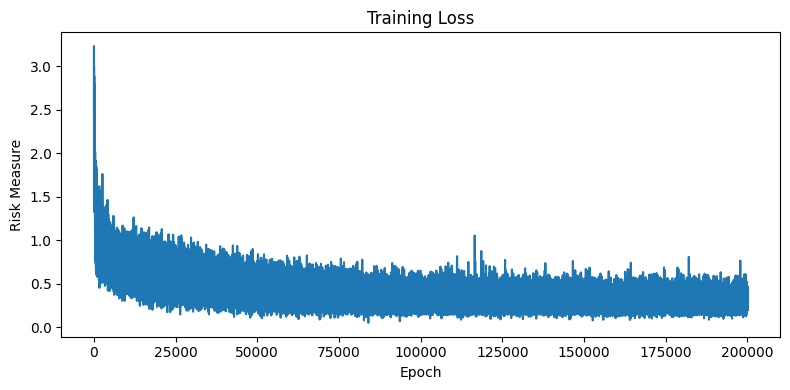

Computing QuantLib hedge on 5000 paths...


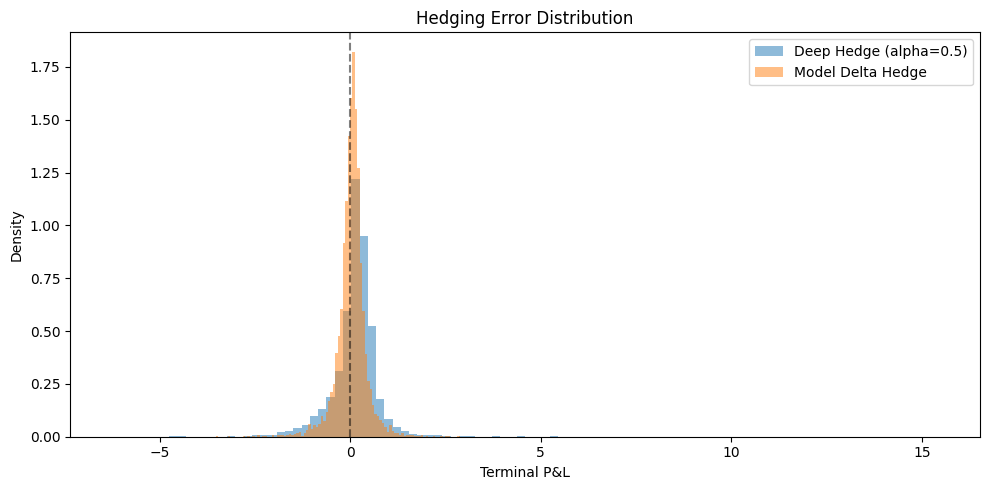

Metric                    Deep Hedge     Model Hedge
--------------------------------------------------
Mean P&L                      0.1121          0.0300
Std P&L                       0.7012          0.3904
CVaR (95%)                    1.6481          0.9874
Min P&L                      -6.2676         -3.5317


In [10]:
# Train model
model, I, S_trade, S1, V, Z, p0, losses = train(
    N=50000, n_epochs=200000, batch_size=256,
    epsilon=0.0, risk_measure='cvar', alpha=0.5
)

# Comparing P&L of classical hedge and model-predicted hedge
PL_deep, PL_model = run_results(
    model, I, S_trade, S1, V, Z, p0, losses,
    epsilon=0.0, alpha=0.5
)

In [ ]:
# Transaction cost experiment
prices, slope = tc_exp(N=20000, n_epochs=50000)